In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

data = pd.read_excel("Online Retail.xlsx", engine="openpyxl")

print("Dataset loaded successfully!")
print("Dataset Shape:", data.shape)
print(data.head())

Dataset loaded successfully!
Dataset Shape: (541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [3]:
print("Dataset Information:")
data.info()

print("\nStatistical Summary:")
print(data.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Statistical Summary:
            Quantity                 InvoiceDate      UnitPrice     CustomerID
count  541909.000000                      541909  541909.000000  406829.000000
mean        9.552250  2011-07-04 13:34:57.156386       4.611114   15287.690570
min    -80995.000000         20

In [4]:
print("Total duplicate rows:", data.duplicated().sum())

Total duplicate rows: 5268


In [5]:
print(data.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
data_clean = data.drop_duplicates().copy()

print("Original dataset shape:", data.shape)
print("Dataset shape after removing duplicates:", data_clean.shape)

Original dataset shape: (541909, 8)
Dataset shape after removing duplicates: (536641, 8)


In [7]:
print(data_clean.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [8]:
data_clean['Description'] = data_clean['Description'].fillna('Unknown Product')

print("Missing descriptions:", data_clean['Description'].isnull().sum())

Missing descriptions: 0


In [9]:
print(data_clean.isnull().sum())

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [10]:
print("Negative quantities:", (data_clean['Quantity'] < 0).sum())
print("Zero quantities:", (data_clean['Quantity'] == 0).sum())
print("Negative prices:", (data_clean['UnitPrice'] < 0).sum())
print("Zero prices:", (data_clean['UnitPrice'] == 0).sum())

Negative quantities: 10587
Zero quantities: 0
Negative prices: 2
Zero prices: 2510


In [11]:
print(data_clean[data_clean['UnitPrice']<0])

       InvoiceNo StockCode      Description  Quantity         InvoiceDate  \
299983   A563186         B  Adjust bad debt         1 2011-08-12 14:51:00   
299984   A563187         B  Adjust bad debt         1 2011-08-12 14:52:00   

        UnitPrice  CustomerID         Country  
299983  -11062.06         NaN  United Kingdom  
299984  -11062.06         NaN  United Kingdom  


In [12]:
sales_data = data_clean[data_clean['UnitPrice'] >= 0].copy()

print("Original cleaned dataset:", data_clean.shape)
print("Sales dataset after removing negative prices:", sales_data.shape)

Original cleaned dataset: (536641, 8)
Sales dataset after removing negative prices: (536639, 8)


In [13]:
sales_data['TotalPrice'] = sales_data['Quantity'] * sales_data['UnitPrice']

print(sales_data[['Quantity', 'UnitPrice', 'TotalPrice']].head())

   Quantity  UnitPrice  TotalPrice
0         6       2.55       15.30
1         6       3.39       20.34
2         8       2.75       22.00
3         6       3.39       20.34
4         6       3.39       20.34


In [14]:
print("Total Sales:", sales_data['TotalPrice'].sum())
print("Average Sales:", sales_data['TotalPrice'].mean())
print("Highest Sale:", sales_data['TotalPrice'].max())
print("Lowest Sale:", sales_data['TotalPrice'].min())

Total Sales: 9748131.074000001
Average Sales: 18.165155857103194
Highest Sale: 168469.6
Lowest Sale: -168469.6


In [15]:
print("Negative sales records:")
print(sales_data[sales_data['TotalPrice'] < 0][
    ['InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'TotalPrice']
].head(10))

Negative sales records:
    InvoiceNo                        Description  Quantity  UnitPrice  \
141   C536379                           Discount        -1      27.50   
154   C536383    SET OF 3 COLOURED  FLYING DUCKS        -1       4.65   
235   C536391     PLASTERS IN TIN CIRCUS PARADE        -12       1.65   
236   C536391   PACK OF 12 PINK PAISLEY TISSUES        -24       0.29   
237   C536391   PACK OF 12 BLUE PAISLEY TISSUES        -24       0.29   
238   C536391  PACK OF 12 RED RETROSPOT TISSUES        -24       0.29   
239   C536391        CHICK GREY HOT WATER BOTTLE       -12       3.45   
240   C536391   PLASTERS IN TIN VINTAGE PAISLEY        -12       1.65   
241   C536391             PLASTERS IN TIN SKULLS       -24       1.65   
939   C536506           JAM MAKING SET WITH JARS        -6       4.25   

     TotalPrice  
141      -27.50  
154       -4.65  
235      -19.80  
236       -6.96  
237       -6.96  
238       -6.96  
239      -41.40  
240      -19.80  
241      -

In [16]:
sales_transactions = sales_data[sales_data['Quantity'] > 0]

return_transactions = sales_data[sales_data['Quantity'] < 0]

print("Total sales transactions:", len(sales_transactions))
print("Total return transactions:", len(return_transactions))

Total sales transactions: 526052
Total return transactions: 10587


In [17]:
total_sales = sales_transactions['TotalPrice'].sum()

total_returns = return_transactions['TotalPrice'].sum()

print("Total Sales Revenue:", total_sales)
print("Total Return Value:", abs(total_returns))

Total Sales Revenue: 10642110.804000001
Total Return Value: 893979.73


In [18]:
net_sales = total_sales - abs(total_returns)

print("Net Sales:", net_sales)

Net Sales: 9748131.074000001


In [19]:
return_percentage = (abs(total_returns) / total_sales) * 100

print("Return Percentage:", round(return_percentage, 2), "%")

Return Percentage: 8.4 %


In [20]:
top_products = (
    sales_transactions.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48375
WHITE HANGING HEART T-LIGHT HOLDER    37876
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
Unknown Product                       32547
RABBIT NIGHT LIGHT                    30739
Name: Quantity, dtype: int64


In [21]:
country_sales = (
    sales_transactions.groupby('Country')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(country_sales)

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: TotalPrice, dtype: float64


In [22]:
sales_transactions['InvoiceDate'] = pd.to_datetime(
    sales_transactions['InvoiceDate']
)

sales_transactions['Month'] = (
    sales_transactions['InvoiceDate'].dt.to_period('M')
)

monthly_sales = sales_transactions.groupby('Month')['TotalPrice'].sum()

print(monthly_sales)

Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: TotalPrice, dtype: float64


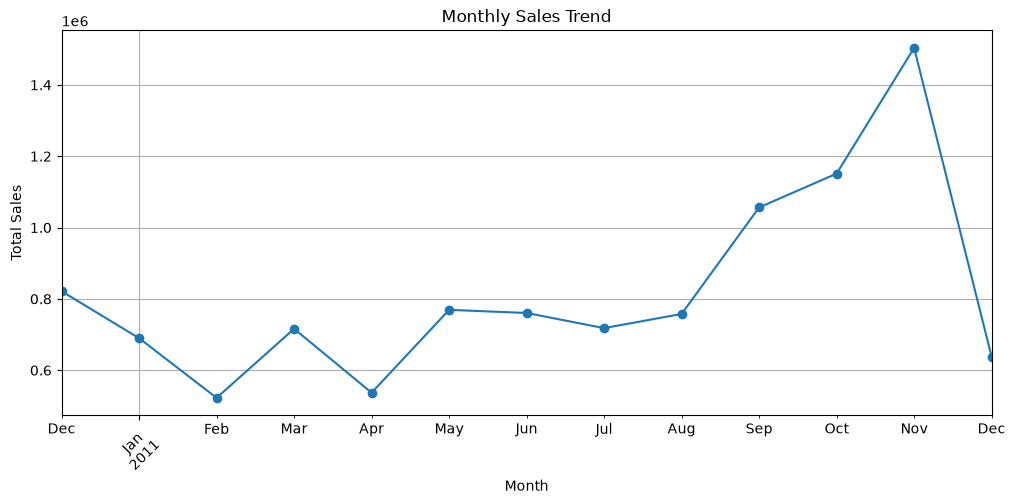

In [23]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind='line', marker='o', figsize=(12, 5))

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

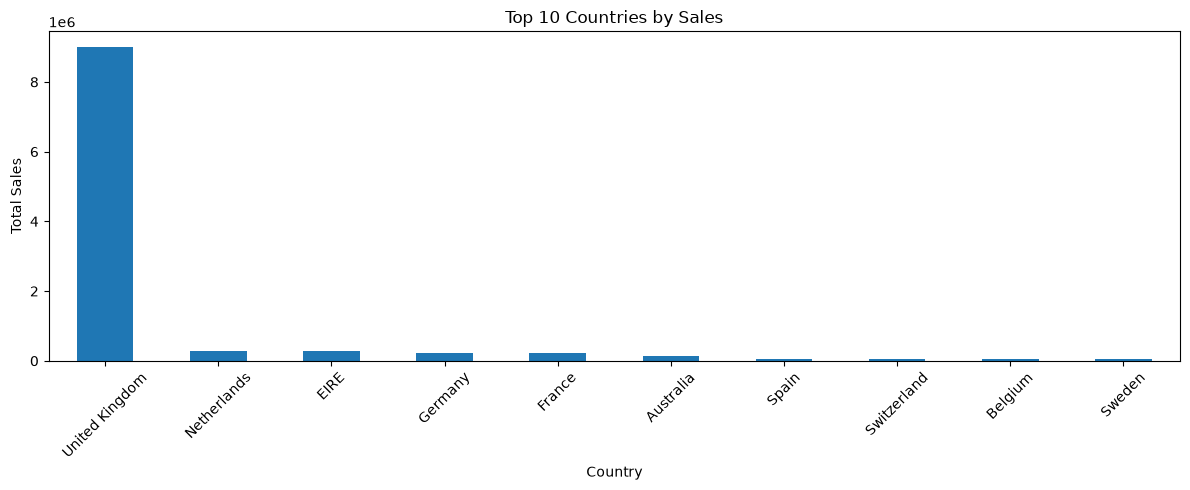

In [24]:
country_sales.head(10).plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Top 10 Countries by Sales')
plt.xlabel('Country')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
top_products_revenue = (
    sales_transactions.groupby('Description')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products_revenue)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: TotalPrice, dtype: float64


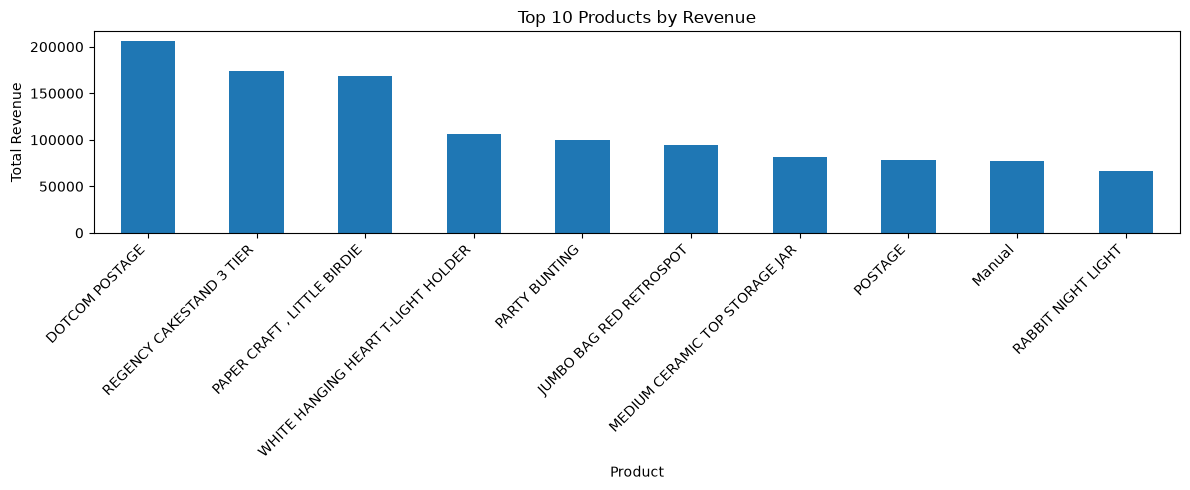

In [26]:
top_products_revenue.plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Product')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [27]:
# Remove non-product entries
actual_products = sales_transactions[
    ~sales_transactions['Description'].isin(
        ['DOTCOM POSTAGE', 'POSTAGE', 'Manual']
    )
]

# Calculate revenue for each actual product
actual_top_products = actual_products.groupby(
    'Description'
)['TotalPrice'].sum().sort_values(ascending=False).head(10)

print("Top 10 Actual Products by Revenue:")
print(actual_top_products)

Top 10 Actual Products by Revenue:
Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: TotalPrice, dtype: float64


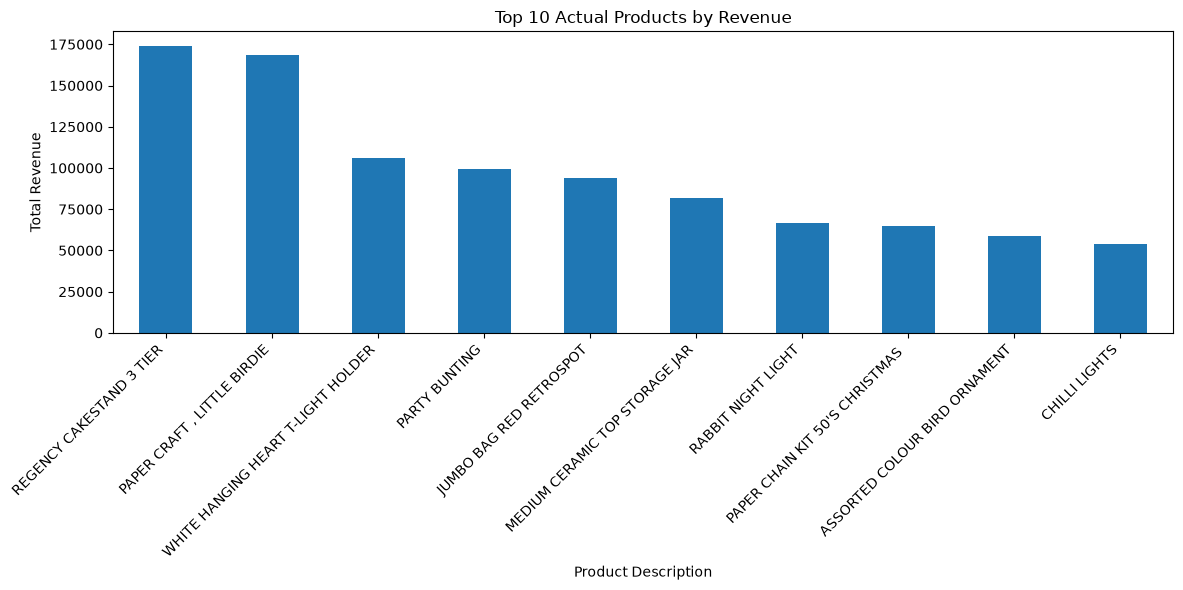

In [28]:
plt.figure(figsize=(12, 6))

actual_top_products.plot(kind='bar')

plt.title('Top 10 Actual Products by Revenue')
plt.xlabel('Product Description')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [29]:
top_customers = sales_transactions.dropna(
    subset=['CustomerID']
).groupby('CustomerID')['TotalPrice'].sum().sort_values(
    ascending=False
).head(10)

print("Top 10 Customers by Revenue:")
print(top_customers)

Top 10 Customers by Revenue:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: TotalPrice, dtype: float64


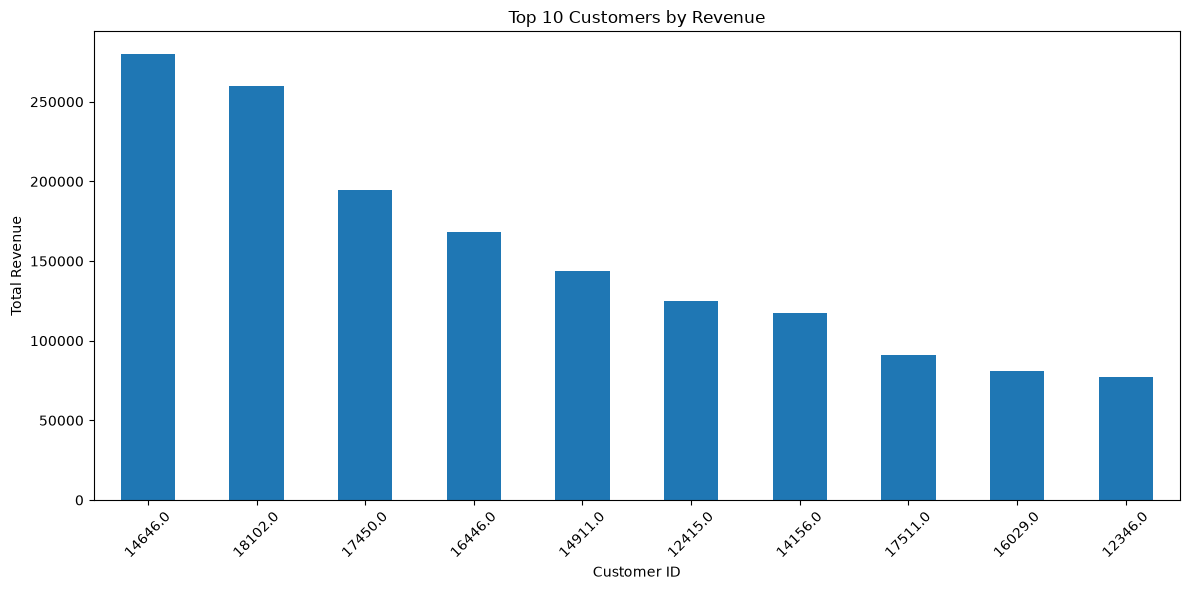

In [30]:
plt.figure(figsize=(12, 6))

top_customers.plot(kind='bar')

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Customer ID')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
total_revenue = sales_transactions['TotalPrice'].sum()

total_orders = sales_transactions['InvoiceNo'].nunique()

unique_customers = sales_transactions['CustomerID'].nunique()

average_order_value = total_revenue / total_orders

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Unique Customers:", unique_customers)
print("Average Order Value:", round(average_order_value, 2))

Total Revenue: 10642110.8
Total Orders: 20726
Unique Customers: 4339
Average Order Value: 513.47


In [32]:
sales_transactions['Day'] = sales_transactions['InvoiceDate'].dt.day_name()

daily_sales = (
    sales_transactions.groupby('Day')['TotalPrice']
    .sum()
)

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_sales = daily_sales.reindex(day_order)

print("Sales by Day of the Week:")
print(daily_sales)

Sales by Day of the Week:
Day
Monday       1775782.071
Tuesday      2175700.511
Wednesday    1847074.380
Thursday     2199292.570
Friday       1837470.491
Saturday             NaN
Sunday        806790.781
Name: TotalPrice, dtype: float64


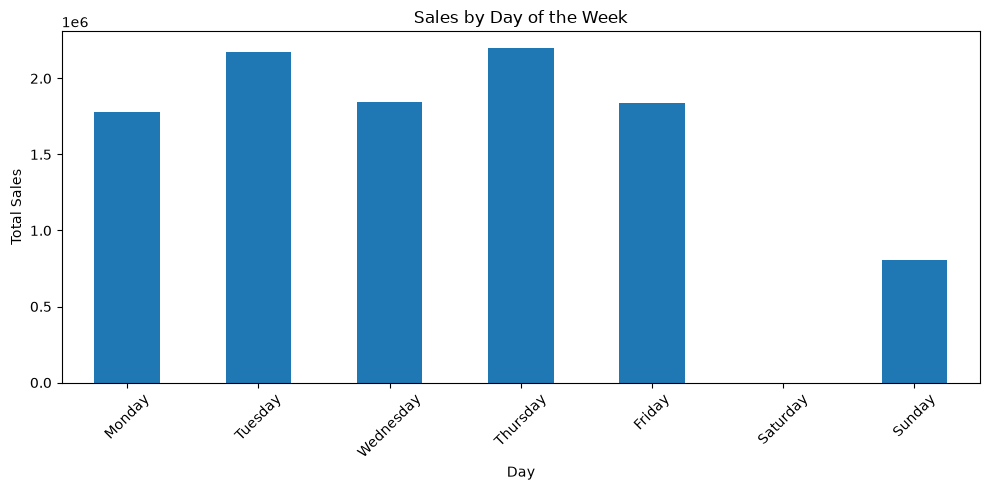

In [33]:
daily_sales.plot(kind='bar', figsize=(10, 5))

plt.title('Sales by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
sales_transactions['Hour'] = sales_transactions['InvoiceDate'].dt.hour

hourly_sales = sales_transactions.groupby('Hour')['TotalPrice'].sum()

print("Sales by Hour:")
print(hourly_sales)

Sales by Hour:
Hour
6           4.250
7       31059.210
8      283750.680
9      990054.991
10    1444814.771
11    1236573.290
12    1439324.660
13    1261195.200
14    1177907.521
15    1350333.310
16     752487.960
17     460963.921
18     144603.610
19      50204.950
20      18832.480
Name: TotalPrice, dtype: float64


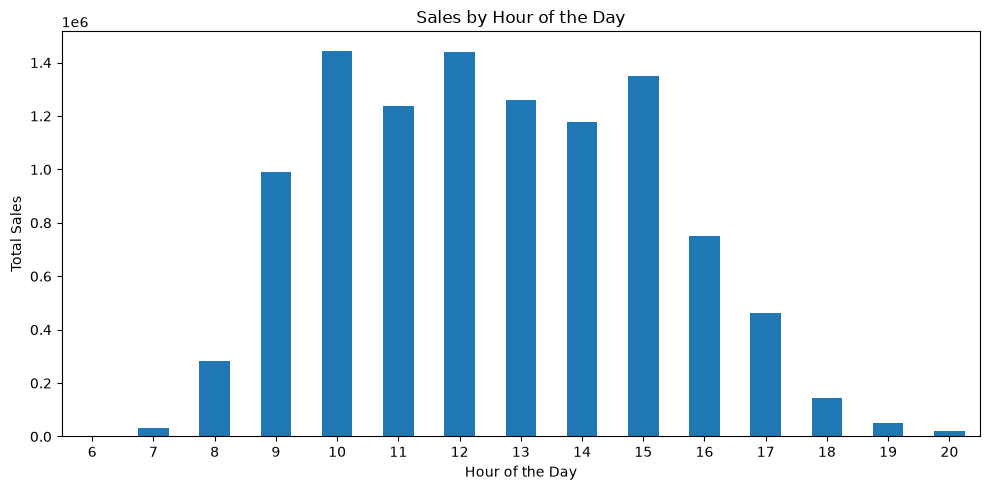

In [35]:
hourly_sales.plot(kind='bar', figsize=(10, 5))

plt.title('Sales by Hour of the Day')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [36]:
highest_sales_hour = hourly_sales.idxmax()
highest_sales_value = hourly_sales.max()

print("Highest Sales Hour:", highest_sales_hour)
print("Total Sales:", highest_sales_value)

Highest Sales Hour: 10
Total Sales: 1444814.771


In [37]:
customer_orders = (
    sales_transactions.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Number of Orders:")
print(customer_orders.head(10))

Top 10 Customers by Number of Orders:
CustomerID
12748.0    210
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     74
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64


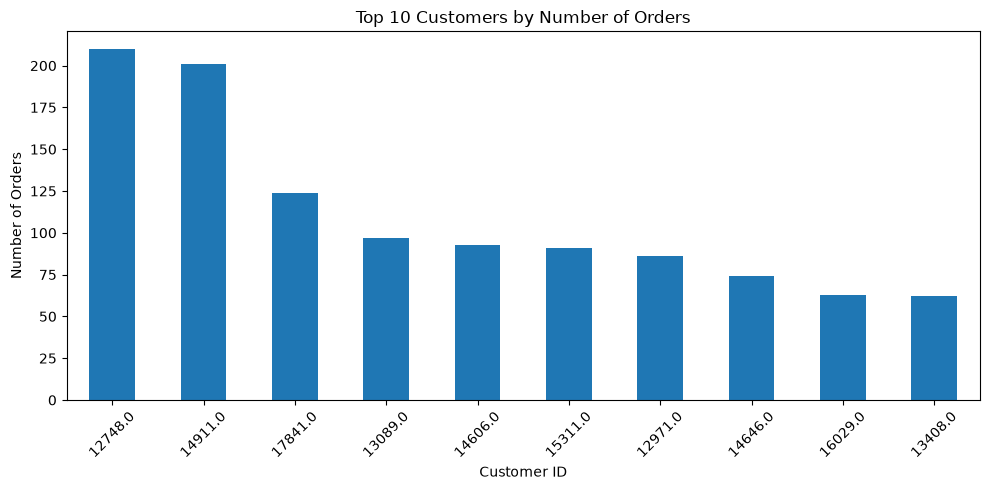

In [38]:
customer_orders.head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Top 10 Customers by Number of Orders')
plt.xlabel('Customer ID')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [39]:
customer_analysis = pd.DataFrame({
    'Total_Orders': customer_orders,
    'Total_Revenue': sales_transactions.dropna(
        subset=['CustomerID']
    ).groupby('CustomerID')['TotalPrice'].sum()
})

customer_analysis = customer_analysis.sort_values(
    by='Total_Revenue',
    ascending=False
)

print("Top 10 Customers by Revenue and Orders:")
print(customer_analysis.head(10))

Top 10 Customers by Revenue and Orders:
            Total_Orders  Total_Revenue
CustomerID                             
14646.0               74      280206.02
18102.0               60      259657.30
17450.0               46      194390.79
16446.0                2      168472.50
14911.0              201      143711.17
12415.0               21      124914.53
14156.0               55      117210.08
17511.0               31       91062.38
16029.0               63       80850.84
12346.0                1       77183.60


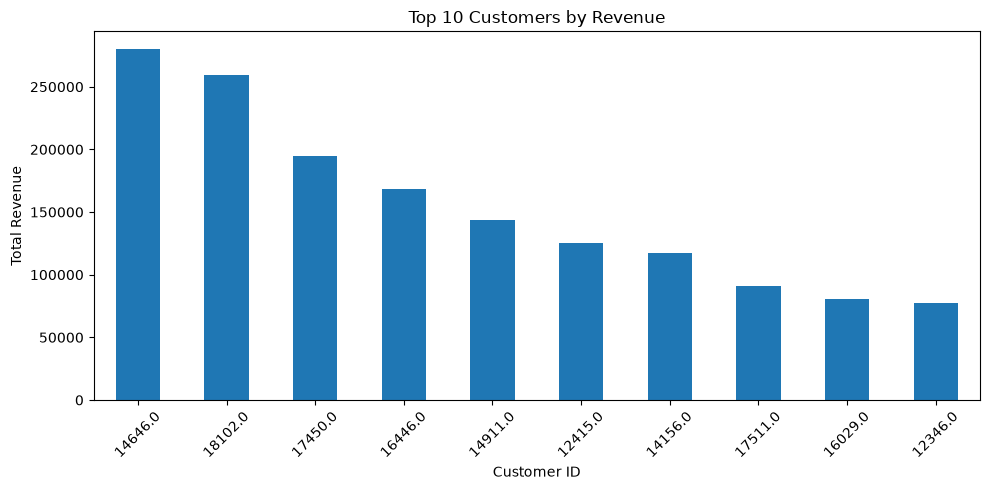

In [40]:
customer_analysis['Total_Revenue'].head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Customer ID')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

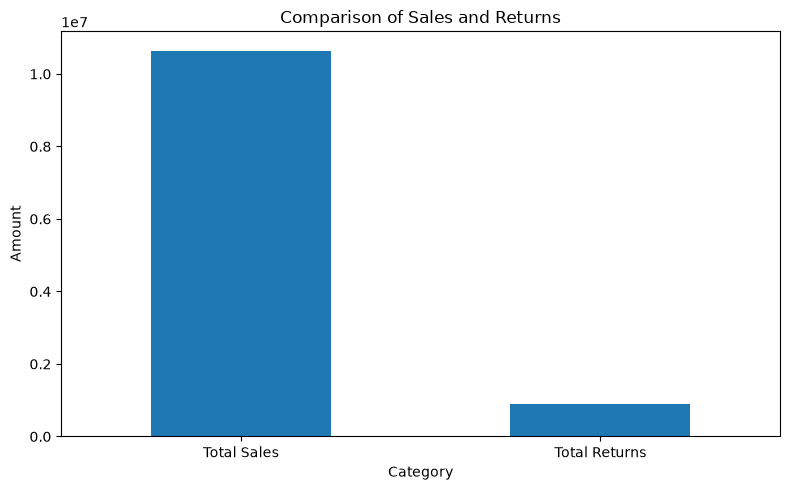

In [41]:
sales_returns = pd.Series({
    'Total Sales': total_sales,
    'Total Returns': abs(total_returns)
})

sales_returns.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Comparison of Sales and Returns')
plt.xlabel('Category')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [42]:
order_values = sales_transactions.groupby('InvoiceNo')['TotalPrice'].sum()

print("Order Value Summary:")
print(order_values.describe())

Order Value Summary:
count     20726.000000
mean        513.466699
std        1750.093548
min           0.000000
25%         137.787500
50%         297.340000
75%         480.355000
max      168469.600000
Name: TotalPrice, dtype: float64


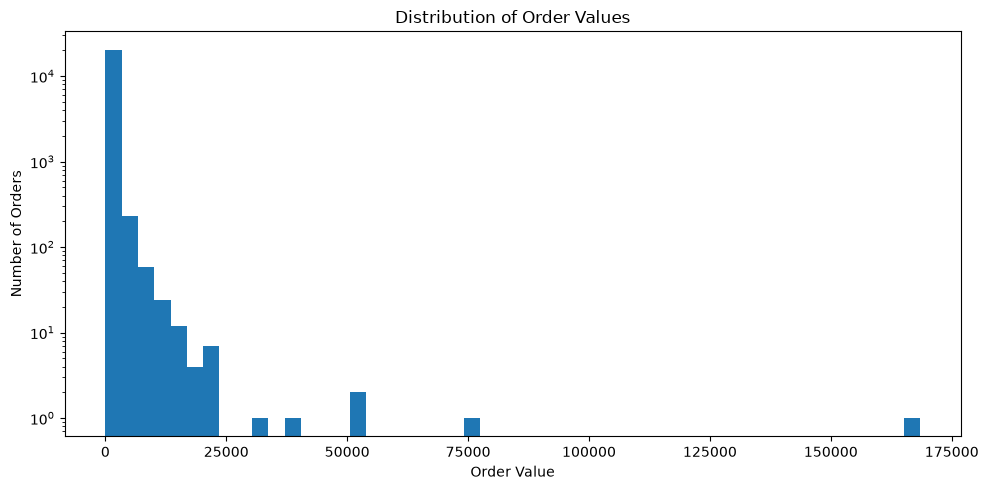

In [44]:
plt.figure(figsize=(10, 5))

plt.hist(order_values, bins=50, log=True)

plt.title('Distribution of Order Values')
plt.xlabel('Order Value')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

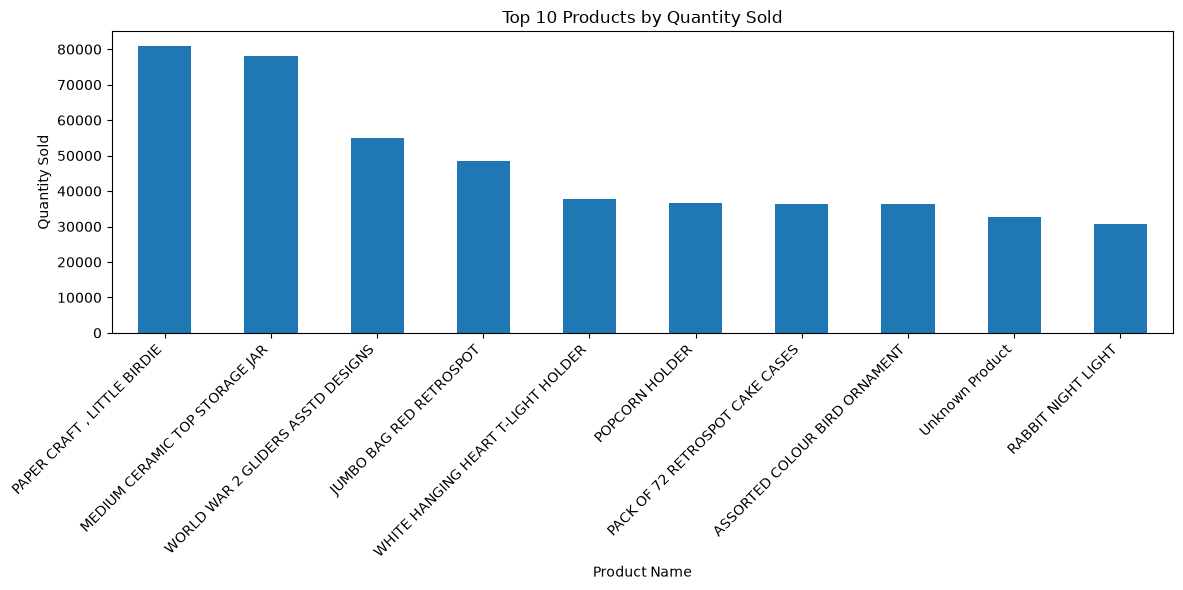

In [45]:
top_products.plot(kind='bar', figsize=(12, 6))

plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Product Name')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Business Insights and Interpretation

Based on the analysis of the Online Retail dataset, the following insights were identified:

1. Overall Revenue: The business generated approximately £10.64 million in sales revenue before accounting for returns.

2. Returns Analysis: The total return value was approximately £893,979.73, representing around 8.4% of sales revenue.

3. Net Sales: After subtracting returns, the net sales value was approximately £9.75 million.

4. Customer Analysis: Customer 14646 generated the highest revenue, while customer 12748 placed the highest number of orders.

5. Product Analysis: Paper Craft, Little Birdie was the highest-selling product by quantity, with 80,995 units sold.

6. Country Analysis: The United Kingdom contributed the highest sales revenue among the countries analysed.

7. Monthly Sales: November 2011 recorded the highest monthly sales in the dataset.

8. Hourly Sales: 10 AM was the hour with the highest recorded sales revenue.

9. Order Value Distribution: Most orders had relatively low order values, while a small number of orders had unusually high values.

## Business Recommendations

Based on the findings from the retail data analysis, the following recommendations are suggested:

1. Focus on Popular Products: Maintain sufficient stock of best-selling products such as Paper Craft, Little Birdie to avoid stock shortages.

2. Improve Customer Retention: Provide loyalty rewards, discounts and special offers to frequent customers to encourage repeat purchases.

3. Reduce Product Returns: Analyse the reasons for product returns and improve product descriptions, quality checks and packaging.

4. Plan Sales Promotions: Use monthly sales trends to plan promotional campaigns during periods of lower sales.

5. Improve Inventory Planning: Use hourly sales patterns to understand customer purchasing activity and plan business operations accordingly.

6. Focus on Major Markets: Continue strengthening sales in the United Kingdom while exploring opportunities in other countries.

7. Understand High-Value Orders: Study unusually large orders to understand customer requirements and identify opportunities for increasing revenue.

## Conclusion

In this project, an end-to-end retail data analysis was performed using the UCI Online Retail dataset.

The project involved data loading, data cleaning, handling missing values, removing duplicate records, analysing sales transactions and exploring customer purchasing behaviour.

Exploratory Data Analysis (EDA) was performed to identify sales trends, popular products, customer behaviour, country-wise sales and product returns. Different visualizations were created using Python libraries such as Matplotlib and Seaborn to understand the data more clearly.

The analysis revealed that the United Kingdom was the major sales market, November 2011 recorded the highest monthly sales, and Paper Craft, Little Birdie was the top-selling product by quantity.

Overall, this project helped develop practical skills in Python, Pandas, data cleaning, exploratory data analysis and data visualization. The findings can help a retail business make better decisions about inventory management, customer retention and sales planning.